# Segmentasi Parasit Malaria pada MP-IDB dengan Pengolahan Citra Klasik

Notebook ini adalah revisi yang mengikuti dokumen utama `docs/report-progress1.md`.

**Ruang lingkup tahap ini**
- Spesies: *Plasmodium falciparum* (seluruh stadium; tidak dibatasi schizont).
- 20 citra dipilih acak dengan seed tetap: **10 citra tuning** dan **10 citra uji**.
- Citra diperkecil **50%** (`INTER_AREA`), mask dan label instance memakai `INTER_NEAREST`.
- Eksperimen A: Otsu multi-level, adaptive threshold, k-means, dan **pixel-if-else sebagai metode tambahan**.
- `pixel-if-else` dan `object-level if-else` dipertahankan sebagai temuan; object-level baru dijalankan pada Eksperimen C.
- Eksperimen B dan C **belum dijalankan** pada tahap ini.

**Catatan metodologis**
- Pemilihan kanal dan tuning threshold hanya memakai 10 citra tuning.
- 10 citra uji tidak dipakai untuk memilih parameter apa pun.
- Semua metode pada Eksperimen A memakai cleanup minimal yang sama.

**Catatan data**
- Dataset falciparum berisi 103 citra dengan 1.267 objek (rata-rata 12,3 objek/citra).
- Berkas citra pada salinan Dataset Ninja ini berupa JPG; anotasi disimpan sebagai
  bitmap 1-bit yang dikompresi di dalam JSON.

In [1]:
from pathlib import Path
import json, base64, zlib, io, random, time, warnings

import numpy as np
import cv2
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

from skimage.filters import threshold_multiotsu
from skimage.measure import label
from skimage.morphology import remove_small_objects

warnings.filterwarnings('ignore')
%matplotlib inline
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 180)


def find_project_root(start=None):
    p = Path(start or Path.cwd()).resolve()
    for cand in [p, *p.parents]:
        if (cand / 'mp-idb-DatasetNinja').is_dir():
            return cand
    raise FileNotFoundError(
        'Folder mp-idb-DatasetNinja tidak ditemukan. Jalankan notebook dari root proyek.'
    )


PROJECT_ROOT = find_project_root()
DATASET_ROOT = PROJECT_ROOT / 'mp-idb-DatasetNinja'
IMG_DIR = DATASET_ROOT / 'ds' / 'img'
ANN_DIR = DATASET_ROOT / 'ds' / 'ann'
RESULTS_DIR = PROJECT_ROOT / 'results' / 'progress1'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
SCALE = 0.5
# Cleanup minimal disesuaikan dengan skala: 50 px pada resolusi penuh -> ~12 px pada 50%.
MIN_AREA = max(10, int(round(50 * SCALE ** 2)))
OBJECT_IOU_THR = 0.10

print('Project root :', PROJECT_ROOT)
print('Image dir    :', IMG_DIR)
print('Annotation   :', ANN_DIR)
print('Results dir  :', RESULTS_DIR)
print('OpenCV       :', cv2.__version__)
print('scikit-image :', __import__('skimage').__version__)
print('Seed / scale :', SEED, '/', SCALE)
print('Min area     :', MIN_AREA, 'px (50% scale)')

Project root : /workspace/home/ia/EleventhMarch/5th/Analisis Citra Biomedik/Project
Image dir    : /workspace/home/ia/EleventhMarch/5th/Analisis Citra Biomedik/Project/mp-idb-DatasetNinja/ds/img
Annotation   : /workspace/home/ia/EleventhMarch/5th/Analisis Citra Biomedik/Project/mp-idb-DatasetNinja/ds/ann
Results dir  : /workspace/home/ia/EleventhMarch/5th/Analisis Citra Biomedik/Project/results/progress1
OpenCV       : 5.0.0
scikit-image : 0.26.0
Seed / scale : 42 / 0.5
Min area     : 12 px (50% scale)


## 1. Inventaris dataset dan seleksi 20 citra falciparum

Anotasi MP-IDB menyimpan mask sebagai bitmap 1-bit yang dikompresi `zlib` lalu `base64`.
Setiap objek punya `origin` `(x, y)`; mask ditempatkan pada koordinat tersebut.

Kriteria seleksi:
1. Semua objek pada citra berkelas `falciparum` (tidak ada kelas campuran).
2. Citra memiliki setidaknya satu objek.
3. Daftar ID diurutkan, lalu diacak dengan `random.Random(42)`.
4. 10 ID pertama menjadi **tuning**, 10 berikutnya menjadi **uji**.

Stadium dicatat sebagai metadata, tetapi **tidak** dipakai untuk memfilter citra.

In [2]:
def annotation_info(ann_path):
    '''Baca metadata anotasi tanpa menyimpan mask resolusi penuh.'''
    d = json.loads(Path(ann_path).read_text())
    h = int(d['size']['height'])
    w = int(d['size']['width'])
    stages = sorted({
        str(t.get('name', '')).lower().replace(' stage', '').strip()
        for t in d.get('tags', [])
        if 'stage' in str(t.get('name', '')).lower()
    })

    objects = []
    for i, obj in enumerate(d.get('objects', []), start=1):
        png = zlib.decompress(base64.b64decode(obj['bitmap']['data']))
        m = np.array(Image.open(io.BytesIO(png)).convert('1'), dtype=np.uint8) > 0
        x, y = map(int, obj['bitmap']['origin'])
        mh, mw = m.shape
        mh = min(mh, h - y)
        mw = min(mw, w - x)
        if mh <= 0 or mw <= 0:
            continue
        mm = m[:mh, :mw]
        objects.append({
            'label': i,
            'area': int(mm.sum()),
            'bbox': (y, x, y + mh, x + mw),
            'classTitle': str(obj.get('classTitle', '')).lower().strip(),
        })

    return {
        'image_id': Path(ann_path).name[:-5],  # remove .json
        'height': h,
        'width': w,
        'stages': stages,
        'objects': objects,
    }


def build_inventory():
    rows = []
    for ann_path in sorted(ANN_DIR.glob('*.json')):
        info = annotation_info(ann_path)
        classes = {o['classTitle'] for o in info['objects']}
        if classes != {'falciparum'} or len(info['objects']) == 0:
            continue
        rows.append({
            'image_id': info['image_id'],
            'species': 'falciparum',
            'stages': info['stages'],
            'n_objects': len(info['objects']),
            'areas': [o['area'] for o in info['objects']],
            'total_area': int(sum(o['area'] for o in info['objects'])),
            'width': info['width'],
            'height': info['height'],
            'image_path': str(IMG_DIR / info['image_id']),
            'ann_path': str(ann_path),
        })
    return pd.DataFrame(rows).sort_values('image_id').reset_index(drop=True)


def select_splits(df, seed=SEED, n_total=20, n_train=10):
    ids = sorted(df['image_id'].tolist())
    rng = random.Random(seed)
    rng.shuffle(ids)
    if len(ids) < n_total:
        raise ValueError(f'Butuh {n_total} citra, hanya tersedia {len(ids)}.')
    train_ids = set(ids[:n_train])
    test_ids = set(ids[n_train:n_total])
    out = df.copy()
    out['split'] = np.where(out['image_id'].isin(train_ids), 'train', 'test')
    out = out[out['image_id'].isin(train_ids | test_ids)].copy()
    out['split'] = pd.Categorical(out['split'], categories=['train', 'test'], ordered=True)
    return out.sort_values(['split', 'image_id']).reset_index(drop=True)


inventory = build_inventory()
selected = select_splits(inventory, seed=SEED)

print('Total citra falciparum :', len(inventory))
print('Total objek            :', int(inventory['n_objects'].sum()))
print('Objek per citra (min/median/mean/max):',
      int(inventory['n_objects'].min()),
      float(inventory['n_objects'].median()),
      round(float(inventory['n_objects'].mean()), 2),
      int(inventory['n_objects'].max()))
print()
print('Komposisi stadium pada 103 citra falciparum:')
stage_counts = inventory['stages'].apply(lambda s: ','.join(s) if s else 'unknown').value_counts()
display(stage_counts.to_frame('n_images'))
print()
print('20 citra terpilih:')
display(selected[['image_id', 'split', 'stages', 'n_objects', 'areas', 'total_area']])
print()
print('Komposisi stadium pada subset terpilih:')
display(selected.assign(stage_key=selected['stages'].apply(lambda s: ','.join(s))).groupby(
    ['stage_key', 'split'], observed=True).size().to_frame('n_images'))

Total citra falciparum : 103
Total objek            : 1267
Objek per citra (min/median/mean/max): 1 7.0 12.3 67

Komposisi stadium pada 103 citra falciparum:


,n_images
stages,
ring,68
schizont,11
"ring,trophozoite",8
"ring,schizont",4
trophozoite,3
gametocyte,3
"gametocyte,ring",2
"ring,schizont,trophozoite",2
"gametocyte,trophozoite",1



20 citra terpilih:


,image_id,split,stages,n_objects,areas,total_area
0,1305121398-0003-R.jpg,train,[ring],1,[6356],6356
1,1305121398-0012-S.jpg,train,[schizont],1,[6575],6575
2,1305121398-0018-S.jpg,train,[schizont],1,[10490],10490
3,1408290968-0003-R.jpg,train,[ring],1,[10417],10417
4,1409171742-0006-R.jpg,train,[ring],3,"[5532, 8416, 7146]",21094
5,1603223711-0006-G.jpg,train,[gametocyte],1,[12070],12070
6,1701151546-0005-R.jpg,train,[ring],25,"[1359, 1193, 1454, 992, 1744, 911, 1031, 1648,...",37745
7,1701151546-0011-R_T.jpg,train,"[ring, trophozoite]",19,"[1429, 1964, 1742, 1462, 1490, 1103, 1146, 130...",31794
8,1701151546-0014-R.jpg,train,[ring],67,"[496, 421, 388, 550, 1674, 480, 457, 369, 257,...",58241
9,1704282807-0001-R.jpg,train,[ring],10,"[4044, 4200, 3446, 4339, 3465, 1822, 3262, 294...",35677



Komposisi stadium pada subset terpilih:


n_images
stage_key        split          
gametocyte       train         1
                 test          1
ring             train         6
                 test          7
ring,schizont    test          1
ring,trophozoite train         1
schizont         train         2
                 test          1

## 2. Memuat 20 citra pada skala 50%

GT biner dan label instance diperkecil dengan nearest-neighbor.
Jika ada label instance yang hilang setelah resize, notebook memberi peringatan agar bisa diperiksa.

In [3]:
def decode_annotation(ann_path):
    '''Decode semua objek menjadi GT biner dan label instance pada resolusi penuh.'''
    d = json.loads(Path(ann_path).read_text())
    h = int(d['size']['height'])
    w = int(d['size']['width'])
    gt = np.zeros((h, w), dtype=np.uint8)
    gt_labels = np.zeros((h, w), dtype=np.int32)
    objects = []

    for i, obj in enumerate(d.get('objects', []), start=1):
        png = zlib.decompress(base64.b64decode(obj['bitmap']['data']))
        m = np.array(Image.open(io.BytesIO(png)).convert('1'), dtype=np.uint8) > 0
        x, y = map(int, obj['bitmap']['origin'])
        mh, mw = m.shape
        mh = min(mh, h - y)
        mw = min(mw, w - x)
        if mh <= 0 or mw <= 0:
            continue
        m = m[:mh, :mw]
        gt[y:y + mh, x:x + mw] |= m.astype(np.uint8)
        sub = gt_labels[y:y + mh, x:x + mw]
        sub[m] = i
        objects.append({
            'label': i,
            'area': int(m.sum()),
            'bbox': (y, x, y + mh, x + mw),
            'classTitle': str(obj.get('classTitle', '')).lower().strip(),
        })

    return gt, gt_labels, objects


def load_record(row):
    bgr = cv2.imread(str(IMG_DIR / row['image_id']), cv2.IMREAD_COLOR)
    if bgr is None:
        raise FileNotFoundError(IMG_DIR / row['image_id'])

    gt_full, labels_full, objects = decode_annotation(row['ann_path'])
    h, w = bgr.shape[:2]
    h2, w2 = int(round(h * SCALE)), int(round(w * SCALE))

    bgr_small = cv2.resize(bgr, (w2, h2), interpolation=cv2.INTER_AREA)
    gt_small = cv2.resize(gt_full, (w2, h2), interpolation=cv2.INTER_NEAREST) > 0
    labels_small = cv2.resize(labels_full, (w2, h2), interpolation=cv2.INTER_NEAREST)

    full_ids = set(np.unique(labels_full).tolist()) - {0}
    small_ids = set(np.unique(labels_small).tolist()) - {0}
    if full_ids != small_ids:
        print(f"  [warning] {row['image_id']}: label berubah setelah resize "
              f"({len(full_ids)} -> {len(small_ids)})")

    max_label = int(labels_small.max()) if labels_small.size else 0
    areas = np.bincount(labels_small.ravel(), minlength=max_label + 1).astype(int)
    object_areas = [int(areas[i]) for i in sorted(small_ids) if i < len(areas)]
    object_areas = [a for a in object_areas if a > 0]

    return {
        'image_id': row['image_id'],
        'species': row['species'],
        'split': str(row['split']),
        'stages': row['stages'],
        'bgr': bgr_small,
        'gt': gt_small,
        'gt_labels': labels_small,
        'shape': bgr_small.shape[:2],
        'n_objects': len(object_areas),
        'areas': object_areas,
        'total_area': int(sum(object_areas)),
    }


records = [load_record(row) for _, row in selected.iterrows()]
TRAIN = [r for r in records if r['split'] == 'train']
TEST = [r for r in records if r['split'] == 'test']

assert len(TRAIN) == 10, len(TRAIN)
assert len(TEST) == 10, len(TEST)
assert not ({r['image_id'] for r in TRAIN} & {r['image_id'] for r in TEST})

print('TRAIN:', len(TRAIN), '| TEST:', len(TEST))
print('Jumlah objek GT  train/test:',
      sum(r['n_objects'] for r in TRAIN), '/', sum(r['n_objects'] for r in TEST))
print('Rata-rata objek/citra train/test:',
      round(np.mean([r['n_objects'] for r in TRAIN]), 2), '/',
      round(np.mean([r['n_objects'] for r in TEST]), 2))
print('Rata-rata fraksi piksel GT train/test:',
      f"{np.mean([r['gt'].mean() for r in TRAIN]):.5%}", '/',
      f"{np.mean([r['gt'].mean() for r in TEST]):.5%}")
print('Ukuran citra setelah resize:', records[0]['shape'])

TRAIN: 10 | TEST: 10
Jumlah objek GT  train/test: 129 / 65
Rata-rata objek/citra train/test: 12.9 / 6.5
Rata-rata fraksi piksel GT train/test: 0.45735% / 0.81078%
Ukuran citra setelah resize: (972, 1296)


## 3. Kanal warna dan preprocessing minimal

Kandidat kanal:
- `gray`, `green`, `L`, `a`, `b`, `S`, dan `P = a - b` (*purple score*).
- Median 3x3 diterapkan pada semua kanal, sesuai preprocessing minimal Eksperimen A.

Polaritas threshold ditetapkan dari sifat kanal:
- `gray`, `green`, `L`, `b`: parasit lebih gelap -> ambil kelas gelap.
- `a`, `S`, `P`: parasit lebih ungu/saturasi tinggi -> ambil kelas terang.

In [4]:
def percentile_norm(x, lo=1, hi=99):
    x = np.asarray(x, dtype=np.float32)
    p1, p2 = np.percentile(x, [lo, hi])
    if p2 <= p1:
        return np.zeros_like(x, dtype=np.float32)
    return np.clip((x - p1) / (p2 - p1), 0.0, 1.0)


def median3(x):
    return cv2.medianBlur(x, 3)


def build_channels(rec):
    lab = cv2.cvtColor(rec['bgr'], cv2.COLOR_BGR2LAB)
    L, a, b = cv2.split(lab)
    hsv = cv2.cvtColor(rec['bgr'], cv2.COLOR_BGR2HSV)
    gray = cv2.cvtColor(rec['bgr'], cv2.COLOR_BGR2GRAY)
    green = rec['bgr'][:, :, 1]

    L, a, b, S, gray, green = [
        median3(x) for x in (L, a, b, hsv[:, :, 1], gray, green)
    ]
    P = a.astype(np.float32) - b.astype(np.float32)
    return {'gray': gray, 'green': green, 'L': L, 'a': a, 'b': b, 'S': S, 'P': P}


CHANNELS = ['gray', 'green', 'L', 'a', 'b', 'S', 'P']
CHANNEL_NAMES = {
    'gray': 'Grayscale', 'green': 'Green (RGB)', 'L': 'Lab L',
    'a': 'Lab a', 'b': 'Lab b', 'S': 'HSV S', 'P': 'Purple (a-b)',
}
CHANNEL_POLARITY = {
    'gray': 'dark', 'green': 'dark', 'L': 'dark', 'a': 'bright',
    'b': 'dark', 'S': 'bright', 'P': 'bright',
}


def channel_uint8(ch, name):
    if name == 'P':
        return (percentile_norm(ch) * 255.0).clip(0, 255).astype(np.uint8)
    return ch


print('Kanal yang diuji:', CHANNELS)
print('Polaritas:', CHANNEL_POLARITY)

Kanal yang diuji: ['gray', 'green', 'L', 'a', 'b', 'S', 'P']
Polaritas: {'gray': 'dark', 'green': 'dark', 'L': 'dark', 'a': 'bright', 'b': 'dark', 'S': 'bright', 'P': 'bright'}


## 4. Pemeriksaan histogram dan effect size pada data tuning

Effect size dihitung sebagai selisih rata-rata intensitas GT dan ring di sekitarnya,
dibagi simpangan baku ring. Nilai absolut besar berarti kanal tersebut memisahkan
parasit dari latar lokal dengan baik. Ini hanya diagnostik, bukan dasar pemilihan akhir.

,mean,median,std
channel,,,
b,2.806,1.893,2.198
P,2.220,1.172,1.894
L,2.103,1.004,1.911
gray,2.092,0.994,1.917
S,2.070,1.054,2.323
green,1.923,0.920,1.752
a,1.141,0.596,1.094


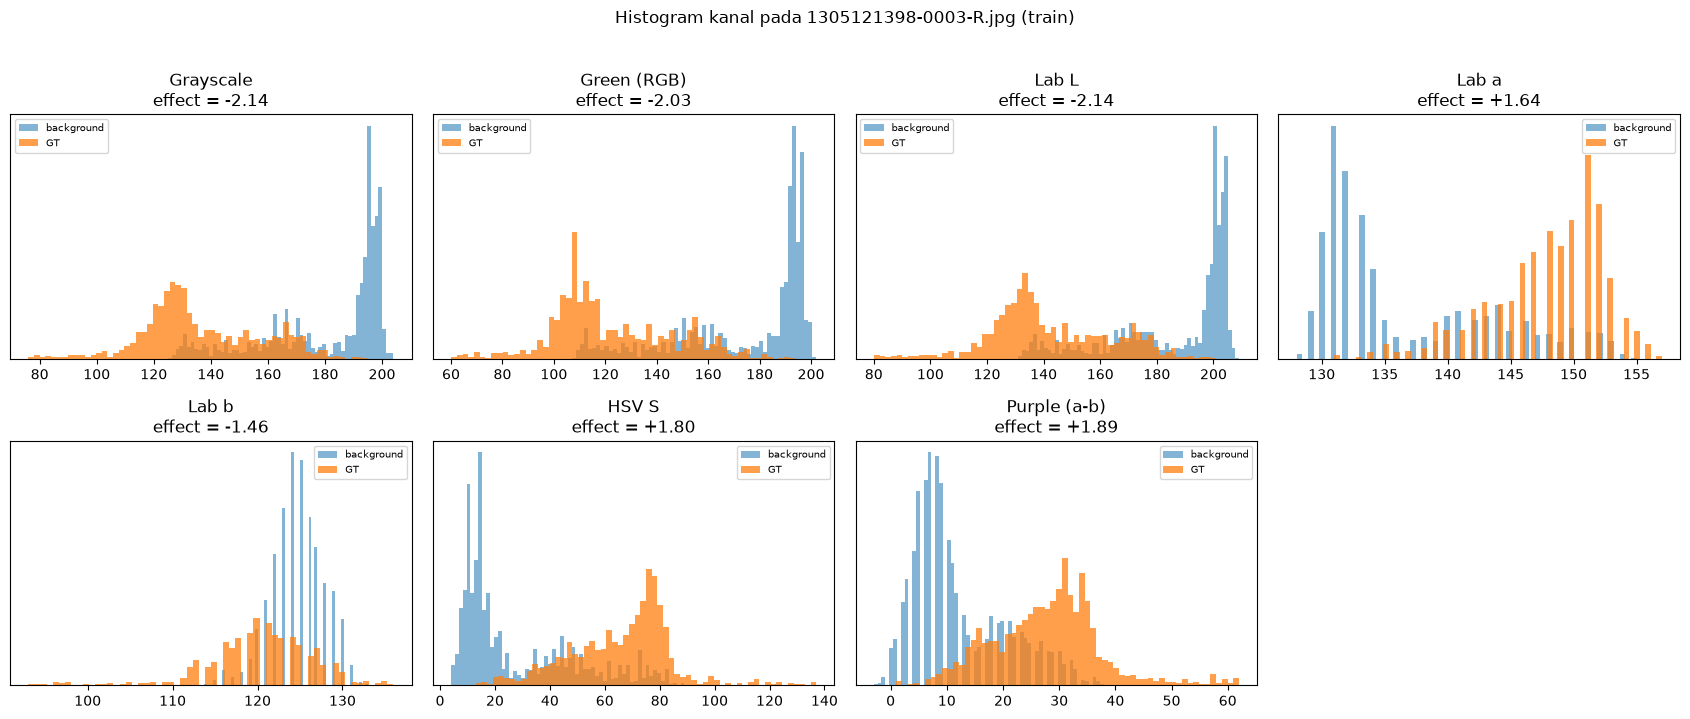

In [5]:
kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (max(3, int(61 * SCALE)),) * 2
)

effect_rows = []
for rec in TRAIN:
    gt = rec['gt']
    ring = (cv2.dilate(gt.astype(np.uint8), kernel) > 0) & (~gt)
    chans = build_channels(rec)
    for name in CHANNELS:
        ch = chans[name]
        inside = ch[gt].astype(np.float32)
        outside = ch[ring].astype(np.float32)
        effect = (inside.mean() - outside.mean()) / (outside.std() + 1e-6)
        effect_rows.append({
            'image_id': rec['image_id'],
            'channel': name,
            'effect_size': float(effect),
            'abs_effect': float(abs(effect)),
        })

channel_effect = pd.DataFrame(effect_rows)
effect_summary = (
    channel_effect.groupby('channel', observed=True)['abs_effect']
    .agg(['mean', 'median', 'std'])
    .sort_values('mean', ascending=False)
    .round(3)
)
display(effect_summary)

# Histogram ditampilkan untuk satu citra train sebagai contoh.
demo = TRAIN[0]
chans = build_channels(demo)
gt = demo['gt']
ring = (cv2.dilate(gt.astype(np.uint8), kernel) > 0) & (~gt)

fig, axes = plt.subplots(2, 4, figsize=(17, 7))
axes = axes.ravel()
for ax, name in zip(axes, CHANNELS):
    ch = chans[name]
    inside = ch[gt].astype(np.float32)
    outside = ch[ring].astype(np.float32)
    effect = (inside.mean() - outside.mean()) / (outside.std() + 1e-6)
    ax.hist(outside, bins=60, alpha=0.55, density=True, label='background')
    ax.hist(inside, bins=60, alpha=0.75, density=True, label='GT')
    ax.set_title(f"{CHANNEL_NAMES[name]}\neffect = {effect:+.2f}")
    ax.legend(fontsize=7)
    ax.set_yticks([])

axes[-1].axis('off')
plt.suptitle(f"Histogram kanal pada {demo['image_id']} (train)", y=1.02)
plt.tight_layout()
plt.show()

channel_effect.to_csv(RESULTS_DIR / 'channel_effect_size.csv', index=False)


## 5. Fungsi segmentasi, cleanup, dan metrik

Semua metode memakai cleanup minimal yang sama: komponen dengan luas di bawah
`MIN_AREA` dibuang. Tidak ada morphology atau object-level rule pada Eksperimen A.

Metrik objek memakai IoU >= 0,10 untuk mencocokkan komponen prediksi dengan objek GT.
Implementasi memakai contingency table sekali jalan agar tetap cepat ketika threshold
global menghasilkan ratusan atau ribuan komponen.

In [6]:
def min_cleanup(mask, min_area=MIN_AREA):
    mask = np.asarray(mask).astype(bool)
    if mask.sum() == 0:
        return mask
    return remove_small_objects(mask, max_size=max(1, min_area - 1), connectivity=2)


def seg_multiotsu(img_u8, classes=3, polarity='dark'):
    try:
        th = threshold_multiotsu(img_u8, classes=classes)
    except Exception:
        return np.zeros(img_u8.shape, dtype=bool)
    if polarity == 'dark':
        return img_u8 < th[0]
    return img_u8 > th[-1]


def seg_adaptive(img_u8, block=25, C=5, polarity='dark'):
    block = int(block)
    if block % 2 == 0:
        block += 1
    typ = cv2.THRESH_BINARY_INV if polarity == 'dark' else cv2.THRESH_BINARY
    return cv2.adaptiveThreshold(
        img_u8, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, typ, block, C
    ).astype(bool)


def pixel_metrics(pred, gt):
    pred = np.asarray(pred).astype(bool)
    gt = np.asarray(gt).astype(bool)
    tp = int(np.logical_and(pred, gt).sum())
    fp = int(np.logical_and(pred, ~gt).sum())
    fn = int(np.logical_and(~pred, gt).sum())
    dice = 2 * tp / (2 * tp + fp + fn + 1e-9)
    iou = tp / (tp + fp + fn + 1e-9)
    precision = tp / (tp + fp + 1e-9)
    recall = tp / (tp + fn + 1e-9)
    return {
        'dice': float(dice), 'iou': float(iou),
        'pixel_precision': float(precision), 'pixel_recall': float(recall),
        'tp': tp, 'fp': fp, 'fn': fn,
    }


def object_metrics(pred, gt_labels, iou_thr=OBJECT_IOU_THR):
    '''Object-level matching memakai IoU >= iou_thr, dihitung dari contingency table.'''
    pred = np.asarray(pred).astype(bool)
    pred_lab = label(pred, connectivity=2)
    n_pred = int(pred_lab.max())
    gt_ids = np.unique(gt_labels)
    gt_ids = gt_ids[gt_ids > 0]
    n_gt = int(len(gt_ids))

    if n_pred == 0 or n_gt == 0:
        return {
            'n_gt': n_gt, 'n_pred': n_pred,
            'gt_detected': 0, 'pred_matched': 0,
            'obj_recall': 0.0, 'obj_precision': 0.0, 'obj_fp': n_pred,
        }

    g = gt_labels.ravel().astype(np.int64)
    p = pred_lab.ravel().astype(np.int64)
    valid = (g > 0) & (p > 0)
    pair = g[valid] * (n_pred + 1) + p[valid]
    uniq, counts = np.unique(pair, return_counts=True)
    pair_gt = uniq // (n_pred + 1)
    pair_pred = uniq % (n_pred + 1)

    gt_areas = np.bincount(g, minlength=int(gt_ids.max()) + 1)
    pred_areas = np.bincount(p, minlength=n_pred + 1)

    best_gt = {}
    best_pred = {}
    for gid, pid, inter in zip(pair_gt.tolist(), pair_pred.tolist(), counts.tolist()):
        union = int(gt_areas[gid] + pred_areas[pid] - inter)
        if union <= 0:
            continue
        iou = inter / union
        if iou > best_gt.get(gid, 0.0):
            best_gt[gid] = iou
        if iou > best_pred.get(pid, 0.0):
            best_pred[pid] = iou

    detected = int(sum(v >= iou_thr for v in best_gt.values()))
    matched = int(sum(v >= iou_thr for v in best_pred.values()))
    return {
        'n_gt': n_gt, 'n_pred': n_pred,
        'gt_detected': detected, 'pred_matched': matched,
        'obj_recall': float(detected / n_gt),
        'obj_precision': float(matched / n_pred),
        'obj_fp': int(n_pred - matched),
    }


print('Fungsi segmentasi dan metrik siap.')

Fungsi segmentasi dan metrik siap.


## 6. Pemilihan kanal untuk Otsu dan adaptive threshold

Kanal dipilih **hanya dari 10 citra tuning**. Untuk setiap kanal dan metode,
dihitung Dice per citra, lalu dirata-ratakan. Kanal dengan rata-rata Dice tertinggi
dipakai untuk Otsu dan adaptive pada data uji.

k-means dan pixel-if-else tetap memakai vektor `[L, P, S]` karena membutuhkan
informasi warna, bukan satu kanal intensitas.

In [7]:
selection_rows = []
for rec in TRAIN:
    chans = build_channels(rec)
    for name in CHANNELS:
        u8 = channel_uint8(chans[name], name)
        masks = {
            'Otsu multilevel 3': seg_multiotsu(
                u8, classes=3, polarity=CHANNEL_POLARITY[name]
            ),
            'Adaptive threshold': seg_adaptive(
                u8, block=int(51 * SCALE), C=5, polarity=CHANNEL_POLARITY[name]
            ),
        }
        for method_name, mask in masks.items():
            pred = min_cleanup(mask)
            m = pixel_metrics(pred, rec['gt'])
            selection_rows.append({
                'image_id': rec['image_id'],
                'channel': name,
                'method': method_name,
                'dice': m['dice'],
                'iou': m['iou'],
                'pixel_precision': m['pixel_precision'],
                'pixel_recall': m['pixel_recall'],
            })

channel_selection = pd.DataFrame(selection_rows)
channel_summary = (
    channel_selection.groupby(['channel', 'method'], observed=True)['dice']
    .agg(['mean', 'median', 'std'])
    .round(4)
)
display(channel_summary)

channel_rank = (
    channel_selection.groupby('channel', observed=True)['dice'].mean()
    .sort_values(ascending=False)
)
print('Ranking kanal untuk threshold (mean Dice pada train):')
print(channel_rank.round(4).to_string())

SELECTED_CHANNEL = str(channel_rank.index[0])
print('\nKanal terpilih untuk Otsu/adaptive:', SELECTED_CHANNEL,
      f'({CHANNEL_NAMES[SELECTED_CHANNEL]})')

channel_selection.to_csv(RESULTS_DIR / 'channel_selection.csv', index=False)

mean  median     std
channel method                                    
L       Adaptive threshold  0.0260  0.0260  0.0173
        Otsu multilevel 3   0.0275  0.0203  0.0261
P       Adaptive threshold  0.0100  0.0080  0.0075
        Otsu multilevel 3   0.0236  0.0165  0.0157
S       Adaptive threshold  0.0062  0.0061  0.0032
        Otsu multilevel 3   0.0155  0.0135  0.0084
a       Adaptive threshold  0.0091  0.0065  0.0069
        Otsu multilevel 3   0.0180  0.0152  0.0141
b       Adaptive threshold  0.0972  0.0589  0.0832
        Otsu multilevel 3   0.0711  0.0367  0.0765
gray    Adaptive threshold  0.0260  0.0249  0.0177
        Otsu multilevel 3   0.0267  0.0189  0.0254
green   Adaptive threshold  0.0214  0.0198  0.0138
        Otsu multilevel 3   0.0229  0.0180  0.0197

Ranking kanal untuk threshold (mean Dice pada train):
channel
b        0.0842
L        0.0267
gray     0.0263
green    0.0221
P        0.0168
a        0.0135
S        0.0108

Kanal terpilih untuk Otsu/adaptive: b (Lab b)


## 7. Pixel-if-else sebagai metode tambahan

Pixel-if-else memakai tiga fitur ternormalisasi:
`L_n` (lightness), `P_n` (*purple score*), dan `S_n` (saturasi).

Aturannya:

```
mask = (L_n < t_L) & (P_n > t_P) & (S_n > t_S)
```

Threshold `t_L`, `t_P`, `t_S` dicari pada 10 citra tuning memakai weighted pixel sample:
foreground dan background disampel seimbang, lalu skor Dice dikoreksi dengan prevalensi
aslinya. Data uji tidak dipakai pada tahap ini.

In [8]:
def pixel_features(rec):
    ch = build_channels(rec)
    return {
        'L': ch['L'], 'P': ch['P'], 'S': ch['S'],
        'L_n': percentile_norm(ch['L']),
        'P_n': percentile_norm(ch['P']),
        'S_n': percentile_norm(ch['S']),
    }


def make_weighted_sample(gt, n_fg=15000, n_bg=15000, seed=SEED):
    g = np.asarray(gt).astype(bool).ravel()
    fg = np.flatnonzero(g)
    bg = np.flatnonzero(~g)
    rng = np.random.default_rng(seed)
    nf = min(len(fg), n_fg)
    nb = min(len(bg), n_bg)
    fi = rng.choice(fg, size=nf, replace=False)
    bi = rng.choice(bg, size=nb, replace=False)
    wf = len(fg) / max(nf, 1)
    wb = len(bg) / max(nb, 1)
    return fi, bi, wf, wb


def tune_pixel_ifelse(train_records, seed=SEED):
    bundles = []
    for rec in train_records:
        feat = pixel_features(rec)
        fi, bi, wf, wb = make_weighted_sample(rec['gt'], seed=seed)
        bundles.append({
            'Lf': feat['L_n'].ravel()[fi], 'Pf': feat['P_n'].ravel()[fi],
            'Sf': feat['S_n'].ravel()[fi],
            'Lb': feat['L_n'].ravel()[bi], 'Pb': feat['P_n'].ravel()[bi],
            'Sb': feat['S_n'].ravel()[bi],
            'wf': wf, 'wb': wb,
        })

    tLs = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60]
    tPs = [0.60, 0.70, 0.80, 0.90, 0.95]
    tSs = [0.40, 0.50, 0.60, 0.70, 0.80, 0.90]
    best = None

    for tL in tLs:
        for tP in tPs:
            for tS in tSs:
                scores = []
                for b in bundles:
                    pf = (b['Lf'] < tL) & (b['Pf'] > tP) & (b['Sf'] > tS)
                    pb = (b['Lb'] < tL) & (b['Pb'] > tP) & (b['Sb'] > tS)
                    tp = pf.sum() * b['wf']
                    fn = (~pf).sum() * b['wf']
                    fp = pb.sum() * b['wb']
                    scores.append(2 * tp / (2 * tp + fp + fn + 1e-9))
                mean_score = float(np.mean(scores))
                if best is None or mean_score > best[0]:
                    best = (mean_score, tL, tP, tS)

    score, tL, tP, tS = best
    params = {
        't_L': float(tL), 't_P': float(tP), 't_S': float(tS),
        'use_texture': False, 't_core': 0.08,
    }
    return params, score


def pixel_mask(feat, params):
    m = (
        (feat['L_n'] < params['t_L']) &
        (feat['P_n'] > params['t_P']) &
        (feat['S_n'] > params['t_S'])
    )
    return m


if_else_params, if_else_train_score = tune_pixel_ifelse(TRAIN, seed=SEED)
print('Pixel-if-else params (tuning):', if_else_params)
print('Weighted train Dice         :', round(if_else_train_score, 4))

Pixel-if-else params (tuning): {'t_L': 0.2, 't_P': 0.95, 't_S': 0.4, 'use_texture': False, 't_core': 0.08}
Weighted train Dice         : 0.1058


## 8. Eksperimen A - perbandingan metode segmentasi

Empat metode dievaluasi pada 10 citra uji:
1. Otsu multilevel 3 kelas pada kanal terpilih,
2. Adaptive threshold pada kanal terpilih,
3. k-means k=3 pada `[L, P, S]`,
4. Pixel-if-else (metode tambahan) dengan threshold dari tuning.

Semua memakai cleanup minimal yang sama.

In [9]:
def seg_kmeans(feat, k=3, seed=SEED, max_sample=80000):
    L_n, P_n, S_n = feat['L_n'], feat['P_n'], feat['S_n']
    h, w = L_n.shape
    X = np.stack([L_n, P_n, S_n], axis=-1).reshape(-1, 3).astype(np.float32)

    rng = np.random.default_rng(seed)
    n = min(max_sample, len(X))
    idx = rng.choice(len(X), size=n, replace=False)
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 50, 0.2)
    _, _, centers = cv2.kmeans(
        X[idx], k, None, criteria, 3, cv2.KMEANS_PP_CENTERS
    )

    # Parasit: ungu (P tinggi), saturasi tinggi (S tinggi), relatif gelap (L rendah).
    score = centers[:, 1] + centers[:, 2] - 0.5 * centers[:, 0]
    chosen = int(np.argmax(score))

    labels = np.empty(len(X), dtype=np.uint8)
    for start in range(0, len(X), 500000):
        chunk = X[start:start + 500000]
        dist = ((chunk[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
        labels[start:start + len(chunk)] = np.argmin(dist, axis=1)
    return labels.reshape(h, w) == chosen


METHODS = [
    'Otsu multilevel 3',
    'Adaptive threshold',
    'k-means k=3',
    'Pixel if-else (tambahan)',
]

exp_a_rows = []
a_masks = {}

for rec in TRAIN + TEST:
    chans = build_channels(rec)
    feat = pixel_features(rec)
    u8 = channel_uint8(chans[SELECTED_CHANNEL], SELECTED_CHANNEL)

    preds = {
        'Otsu multilevel 3': min_cleanup(
            seg_multiotsu(u8, classes=3, polarity=CHANNEL_POLARITY[SELECTED_CHANNEL])
        ),
        'Adaptive threshold': min_cleanup(
            seg_adaptive(
                u8, block=int(51 * SCALE), C=5,
                polarity=CHANNEL_POLARITY[SELECTED_CHANNEL],
            )
        ),
        'k-means k=3': min_cleanup(seg_kmeans(feat, k=3)),
        'Pixel if-else (tambahan)': min_cleanup(pixel_mask(feat, if_else_params)),
    }

    for method_name, pred in preds.items():
        pm = pixel_metrics(pred, rec['gt'])
        om = object_metrics(pred, rec['gt_labels'])
        exp_a_rows.append({
            'split': rec['split'],
            'image_id': rec['image_id'],
            'stages': ','.join(rec['stages']),
            'n_objects': rec['n_objects'],
            'method': method_name,
            **pm,
            **om,
        })
        if rec['split'] == 'test':
            a_masks[(rec['image_id'], method_name)] = pred

experiment_a = pd.DataFrame(exp_a_rows)

test_a = experiment_a[experiment_a['split'] == 'test'].copy()
display(
    test_a.groupby('method', observed=True)[['dice', 'iou', 'pixel_precision',
                                             'pixel_recall', 'obj_recall',
                                             'obj_precision', 'obj_fp']]
    .agg(['mean', 'median', 'std'])
    .round(4)
)

experiment_a.to_csv(RESULTS_DIR / 'experiment_a.csv', index=False)

dice                     iou                 pixel_precision                 pixel_recall                 obj_recall                 obj_precision  \
                            mean  median     std    mean  median     std            mean  median     std         mean  median     std       mean  median     std          mean   
method                                                                                                                                                                           
Adaptive threshold        0.0972  0.0910  0.0411  0.0515  0.0477  0.0229          0.3480  0.3172  0.2679       0.1050  0.0666  0.1057     0.1000  0.0000  0.3162        0.0001   
Otsu multilevel 3         0.0878  0.0270  0.1423  0.0518  0.0137  0.0883          0.0712  0.0143  0.1310       0.2725  0.1732  0.2935     0.3419  0.2719  0.3912        0.0117   
Pixel if-else (tambahan)  0.0845  0.0410  0.0969  0.0467  0.0209  0.0560          0.1508  0.0480  0.2053       0.0949  0.0438  0.1515     0.1469  0.0000  0.3122        0.0146   
k-means k=3               0.0317  0.0158  0.0395  0.0165  0.0080  0.0209          0.0166  0.0080  0.0211       0.6031  0.6553  0.3520     0.6833  1.0000  0.4335        0.0379   

                                         obj_fp                   
                          median     std   mean median       std  
method                                                            
Adaptive threshold        0.0000  0.0003  159.9   43.5  350.9253  
Otsu multilevel 3         0.0042  0.0218  321.5  172.0  353.4626  
Pixel if-else (tambahan)  0.0000  0.0270   36.8   30.5   22.1801  
k-means k=3               0.0182  0.0551  202.2  141.5  149.8368

## 9. Visualisasi overlay

GT berwarna hijau, prediksi berwarna merah. Area yang tumpang-tindih menjadi
campuran kuning/coklat. Visualisasi memakai downscale hanya untuk tampilan;
evaluasi tetap pada resolusi 50%.

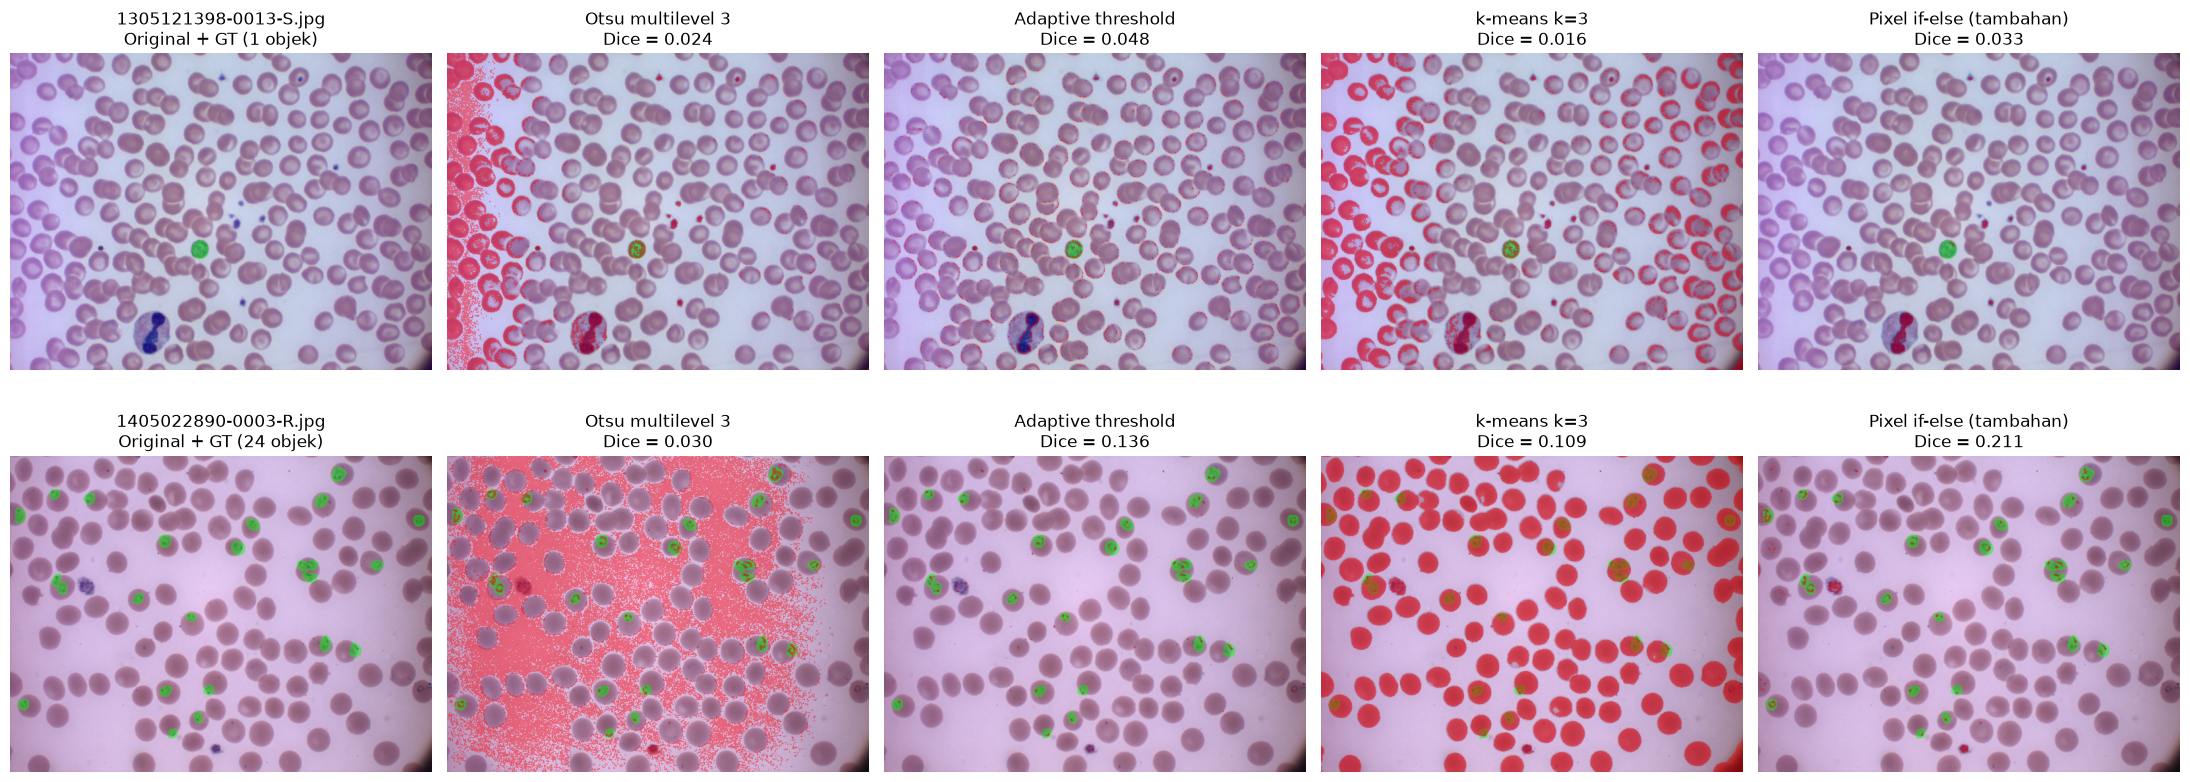

In [10]:
def overlay_small(bgr, gt, pred, width=640):
    h, w = bgr.shape[:2]
    scale = width / w
    nw, nh = width, max(1, int(h * scale))
    img = cv2.resize(bgr, (nw, nh), interpolation=cv2.INTER_AREA)
    g = cv2.resize(gt.astype(np.uint8), (nw, nh), interpolation=cv2.INTER_NEAREST) > 0
    p = cv2.resize(pred.astype(np.uint8), (nw, nh), interpolation=cv2.INTER_NEAREST) > 0

    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).astype(np.float32)
    out = rgb.copy()
    out[g] = 0.55 * out[g] + 0.45 * np.array([0, 255, 0], dtype=np.float32)
    out[p] = 0.55 * out[p] + 0.45 * np.array([255, 0, 0], dtype=np.float32)
    return np.clip(out, 0, 255).astype(np.uint8)


viz_recs = sorted(TEST, key=lambda r: r['n_objects'])
if len(viz_recs) > 2:
    viz_recs = [viz_recs[0], viz_recs[-1]]

fig, axes = plt.subplots(len(viz_recs), 1 + len(METHODS),
                         figsize=(22, 4.3 * len(viz_recs)), squeeze=False)

for row_i, rec in enumerate(viz_recs):
    axes[row_i, 0].imshow(overlay_small(rec['bgr'], rec['gt'], np.zeros_like(rec['gt'])))
    axes[row_i, 0].set_title(f"{rec['image_id']}\nOriginal + GT ({rec['n_objects']} objek)")
    axes[row_i, 0].axis('off')

    for col_i, method in enumerate(METHODS, start=1):
        pred = a_masks[(rec['image_id'], method)]
        d = pixel_metrics(pred, rec['gt'])['dice']
        axes[row_i, col_i].imshow(overlay_small(rec['bgr'], rec['gt'], pred))
        axes[row_i, col_i].set_title(f"{method}\nDice = {d:.3f}")
        axes[row_i, col_i].axis('off')

plt.tight_layout()
fig.savefig(RESULTS_DIR / 'experiment_a_overlay.png', dpi=120, bbox_inches='tight')
plt.show()

## 10. Ringkasan hasil Eksperimen A dan penyimpanan

Tabel ringkas berisi mean, median, dan std pada 10 citra uji.
Angka ini bersifat eksploratif: 20 citra dipilih acak dari 103 citra falciparum,
dan sebagian besar objek berada pada stadium ring yang sangat kecil.

In [11]:
summary_metrics = [
    'dice', 'iou', 'pixel_precision', 'pixel_recall',
    'obj_recall', 'obj_precision', 'obj_fp', 'n_pred',
]
per_image_dice = test_a.pivot_table(
    index='image_id', columns='method', values='dice'
).round(4)
print('Dice per citra uji:')
display(per_image_dice)

summary = (
    test_a.groupby('method', observed=True)[summary_metrics]
    .agg(['mean', 'median', 'std'])
    .round(4)
)
summary.columns = [f'{a}_{b}' for a, b in summary.columns]
summary = summary.reset_index()
display(summary)

summary.to_csv(RESULTS_DIR / 'experiment_a_summary.csv', index=False)

# Simpan metadata subset pada skala evaluasi (50%).
rec_by_id = {r['image_id']: r for r in records}
selected_out = selected.copy()
selected_out['stages'] = selected_out['stages'].apply(lambda s: ','.join(s))
selected_out['n_objects'] = selected_out['image_id'].map(lambda x: rec_by_id[x]['n_objects'])
selected_out['areas'] = selected_out['image_id'].map(
    lambda x: ','.join(map(str, rec_by_id[x]['areas']))
)
selected_out['total_area'] = selected_out['image_id'].map(
    lambda x: rec_by_id[x]['total_area']
)
selected_out['scale'] = SCALE
selected_out = selected_out.drop(columns=['width', 'height', 'image_path', 'ann_path'])
selected_out.to_csv(RESULTS_DIR / 'selected_images.csv', index=False)

with open(RESULTS_DIR / 'experiment_a_params.json', 'w') as f:
    json.dump({
        'seed': SEED,
        'scale': SCALE,
        'min_area': MIN_AREA,
        'object_iou_threshold': OBJECT_IOU_THR,
        'selected_channel': SELECTED_CHANNEL,
        'channel_polarity': CHANNEL_POLARITY,
        'adaptive_block': int(51 * SCALE),
        'adaptive_C': 5,
        'pixel_if_else_params': if_else_params,
        'pixel_if_else_weighted_train_dice': float(if_else_train_score),
    }, f, indent=2)

test_mean = test_a.groupby('method', observed=True)['dice'].mean().sort_values(ascending=False)
print('Ranking metode berdasarkan mean Dice pada test:')
print(test_mean.round(4).to_string())

main_methods = [m for m in METHODS if not m.startswith('Pixel')]
best_main = test_mean[main_methods].idxmax()
pixel_name = 'Pixel if-else (tambahan)'
pixel_mean = float(test_mean.get(pixel_name, np.nan))
best_main_mean = float(test_mean[best_main])
metric_means = test_a.groupby('method', observed=True)[
    ['dice', 'pixel_precision', 'pixel_recall', 'obj_recall', 'obj_precision', 'obj_fp']
].mean()

lines = [
    '# Ringkasan Eksperimen A',
    '',
    f'- Data: 20 citra P. falciparum (10 tuning, 10 uji), resize {SCALE:.0%}.',
    f'- Kanal terpilih untuk Otsu/adaptive: `{SELECTED_CHANNEL}` ({CHANNEL_NAMES[SELECTED_CHANNEL]}).',
    f'- Metode utama terbaik pada test: `{best_main}` (mean Dice {best_main_mean:.4f}).',
    f'- Pixel-if-else (tambahan) mean Dice: {pixel_mean:.4f}.',
    '',
    '## Mean Dice per metode (test)',
    '',
    '```',
    test_mean.round(4).to_string(),
    '```',
    '',
    '## Catatan',
    '',
]
for method in ['Adaptive threshold', 'Otsu multilevel 3', 'k-means k=3',
               'Pixel if-else (tambahan)']:
    r = metric_means.loc[method]
    lines.append(
        f"- `{method}`: Dice {r['dice']:.4f}; pixel precision {r['pixel_precision']:.3f}, "
        f"pixel recall {r['pixel_recall']:.3f}; object recall {r['obj_recall']:.3f}, "
        f"object precision {r['obj_precision']:.3f}; FP objek {r['obj_fp']:.1f}/citra."
    )
lines += [
    '',
    '- Metode threshold global menangkap area luas (sel darah merah, tepi citra, artefak), '
    'sehingga pixel precision rendah meskipun recall piksel bisa tinggi.',
    '- Pixel-if-else menghasilkan komponen paling sedikit, tetapi recall-nya rendah: '
    'sebagian parasit tidak lolos ambang warna.',
    '- Eksperimen B (CLAHE, koreksi background, tekstur) dan Eksperimen C '
    '(morfologi, filter luas, object-level if-else) belum dijalankan.',
]
(RESULTS_DIR / 'experiment_a_summary.md').write_text('\n'.join(lines))
print('\nFile tersimpan di:', RESULTS_DIR)
for p in sorted(RESULTS_DIR.glob('*')):
    print(' -', p.name)

Dice per citra uji:


method,Adaptive threshold,Otsu multilevel 3,Pixel if-else (tambahan),k-means k=3
image_id,,,,
1305121398-0013-S.jpg,0.0481,0.0243,0.0334,0.0160
1405022890-0003-R.jpg,0.1358,0.0303,0.2110,0.1092
1405022890-0004-R.jpg,0.0746,0.0237,0.1039,0.0983
1408161544-0002-R_S.jpg,0.1425,0.4029,0.1222,0.0262
1409171742-0003-R.jpg,0.1012,0.0298,0.0222,0.0156
1409171742-0004-R.jpg,0.0809,0.0160,0.0129,0.0055
1409171742-0009-R.jpg,0.1076,0.0141,0.0485,0.0347
1409191647-0005-R.jpg,0.0529,0.0309,0.0056,0.0005
1409191647-0007-R.jpg,0.0606,0.0020,0.0000,0.0000


,method,dice_mean,dice_median,dice_std,iou_mean,iou_median,iou_std,pixel_precision_mean,pixel_precision_median,pixel_precision_std,pixel_recall_mean,pixel_recall_median,pixel_recall_std,obj_recall_mean,obj_recall_median,obj_recall_std,obj_precision_mean,obj_precision_median,obj_precision_std,obj_fp_mean,obj_fp_median,obj_fp_std,n_pred_mean,n_pred_median,n_pred_std
0,Adaptive threshold,0.0972,0.0910,0.0411,0.0515,0.0477,0.0229,0.3480,0.3172,0.2679,0.1050,0.0666,0.1057,0.1000,0.0000,0.3162,0.0001,0.0000,0.0003,159.9,43.5,350.9253,160.0,43.5,351.2400
1,Otsu multilevel 3,0.0878,0.0270,0.1423,0.0518,0.0137,0.0883,0.0712,0.0143,0.1310,0.2725,0.1732,0.2935,0.3419,0.2719,0.3912,0.0117,0.0042,0.0218,321.5,172.0,353.4626,323.5,173.0,355.3272
2,Pixel if-else (tambahan),0.0845,0.0410,0.0969,0.0467,0.0209,0.0560,0.1508,0.0480,0.2053,0.0949,0.0438,0.1515,0.1469,0.0000,0.3122,0.0146,0.0000,0.0270,36.8,30.5,22.1801,37.8,31.0,23.7618
3,k-means k=3,0.0317,0.0158,0.0395,0.0165,0.0080,0.0209,0.0166,0.0080,0.0211,0.6031,0.6553,0.3520,0.6833,1.0000,0.4335,0.0379,0.0182,0.0551,202.2,141.5,149.8368,207.0,150.0,147.2081


Ranking metode berdasarkan mean Dice pada test:
method
Adaptive threshold          0.0972
Otsu multilevel 3           0.0878
Pixel if-else (tambahan)    0.0845
k-means k=3                 0.0317

File tersimpan di: /workspace/home/ia/EleventhMarch/5th/Analisis Citra Biomedik/Project/results/progress1
 - channel_effect_size.csv
 - channel_selection.csv
 - experiment_a.csv
 - experiment_a_overlay.png
 - experiment_a_params.json
 - experiment_a_summary.csv
 - experiment_a_summary.md
 - selected_images.csv


## 11. Keterbatasan dan langkah berikutnya

**Keterbatasan tahap ini**
- 20 citra dipilih acak dari 103 citra falciparum; hasil belum mengklaim generalisasi.
- Sebagian besar objek berada pada stadium ring yang sangat kecil, sehingga Dice
  sangat sensitif terhadap selisih beberapa piksel.
- Threshold global pada satu kanal menangkap sel darah merah dan artefak sebagai
  false positive. Ini dilaporkan sebagai temuan, bukan disembunyikan.
- Pixel-if-else adalah metode tambahan; hasilnya tidak boleh dibandingkan secara
  langsung dengan metode utama tanpa catatan bahwa ia memakai tiga fitur dan tuning.

**Langkah berikutnya (belum dikerjakan)**
- Eksperimen B: CLAHE, koreksi background (closing besar), GLCM/LBP, kombinasi,
  serta kontrol negatif opening.
- Eksperimen C: opening/closing, filter luas dengan tiga ambang, dan object-level if-else.
- Penulisan Bab Hasil dan Pembahasan di `docs/report-progress1.md`.